## FACULTY OF ENGINEERING, DESIGN AND TECHNOLOGY 
## DEPARTMENT OF COMPUTING AND TECHNOLOGY
## ADVENT 2026 SEMESTER ASSIGNMENT
## COURSE NAME: DATA MINING, MODELING AND ANALYTICS
## ASSIGNMENT ONE
## Samuel KAMUTUNGYE - B35097

### Project 2.  Concrete Compressive Strength
The objective is to predict the compressive strength of concrete using the proportions of its constituent materials and the curing age.

In [1]:
import pandas as pd

# Load dataset
df = pd.read_csv("Concrete_Data.csv")

# Display dimensions
print("Dataset Shape:", df.shape)

# Preview records
df.head()

Dataset Shape: (1030, 9)


,Cement (kg in a m^3 mixture),Blast Furnace Slag (kg in a m^3 mixture),Fly Ash (kg in a m^3 mixture),Water (kg in a m^3 mixture),Superplasticizer (kg in a m^3 mixture),Coarse Aggregate (kg in a m^3 mixture),Fine Aggregate (kg in a m^3 mixture),Age (day),"Concrete compressive strength (MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [2]:
# Examine Dataset Structure
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                                             Non-Null Count  Dtype  
---  ------                                             --------------  -----  
 0   Cement (kg in a m^3 mixture)                       1030 non-null   float64
 1   Blast Furnace Slag (kg in a m^3 mixture)           1030 non-null   float64
 2   Fly Ash (kg in a m^3 mixture)                      1030 non-null   float64
 3   Water (kg in a m^3 mixture)                        1030 non-null   float64
 4   Superplasticizer (kg in a m^3 mixture)             1030 non-null   float64
 5   Coarse Aggregate (kg in a m^3 mixture)             1030 non-null   float64
 6   Fine Aggregate (kg in a m^3 mixture)               1030 non-null   float64
 7   Age (day)                                          1030 non-null   int64  
 8   Concrete compressive strength (MPa, megapascals)   1030 non-null   float64
dtypes: float64(8), int64

In [3]:
# Summary Statistics
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Cement (kg in a m^3 mixture),1030.0,281.165631,104.507142,102.000000,192.375000,272.900000,350.000000,540.000000
Blast Furnace Slag (kg in a m^3 mixture),1030.0,73.895485,86.279104,0.000000,0.000000,22.000000,142.950000,359.400000
Fly Ash (kg in a m^3 mixture),1030.0,54.187136,63.996469,0.000000,0.000000,0.000000,118.270000,200.100000
Water (kg in a m^3 mixture),1030.0,181.566359,21.355567,121.750000,164.900000,185.000000,192.000000,247.000000
Superplasticizer (kg in a m^3 mixture),1030.0,6.203112,5.973492,0.000000,0.000000,6.350000,10.160000,32.200000
Coarse Aggregate (kg in a m^3 mixture),1030.0,972.918592,77.753818,801.000000,932.000000,968.000000,1029.400000,1145.000000
Fine Aggregate (kg in a m^3 mixture),1030.0,773.578883,80.175427,594.000000,730.950000,779.510000,824.000000,992.600000
Age (day),1030.0,45.662136,63.169912,1.000000,7.000000,28.000000,56.000000,365.000000
"Concrete compressive strength (MPa, megapascals)",1030.0,35.817836,16.705679,2.331808,23.707115,34.442774,46.136287,82.599225


In [4]:
# Check Missing Values
df.isnull().sum()

Cement (kg in a m^3 mixture)                         0
Blast Furnace Slag (kg in a m^3 mixture)             0
Fly Ash (kg in a m^3 mixture)                        0
Water (kg in a m^3 mixture)                          0
Superplasticizer (kg in a m^3 mixture)               0
Coarse Aggregate (kg in a m^3 mixture)               0
Fine Aggregate (kg in a m^3 mixture)                 0
Age (day)                                            0
Concrete compressive strength (MPa, megapascals)     0
dtype: int64

In [5]:
# Check Duplicates
print("Duplicate Rows =", df.duplicated().sum())

Duplicate Rows = 25


In [6]:
# Remove duplicates
df = df.drop_duplicates()

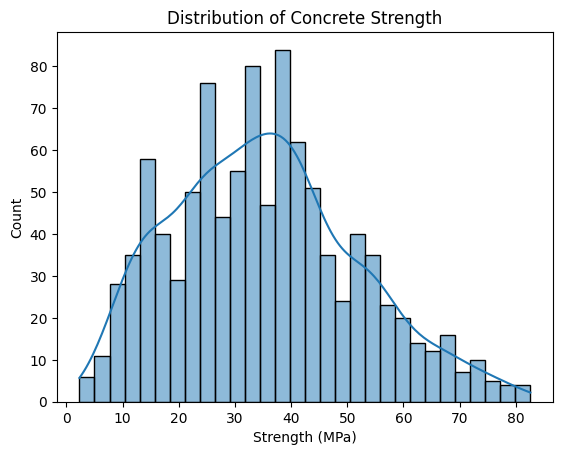

In [7]:
# Examine Target Variable Distribution
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(df.iloc[:, -1], bins=30, kde=True)
plt.title("Distribution of Concrete Strength")
plt.xlabel("Strength (MPa)")
plt.show()

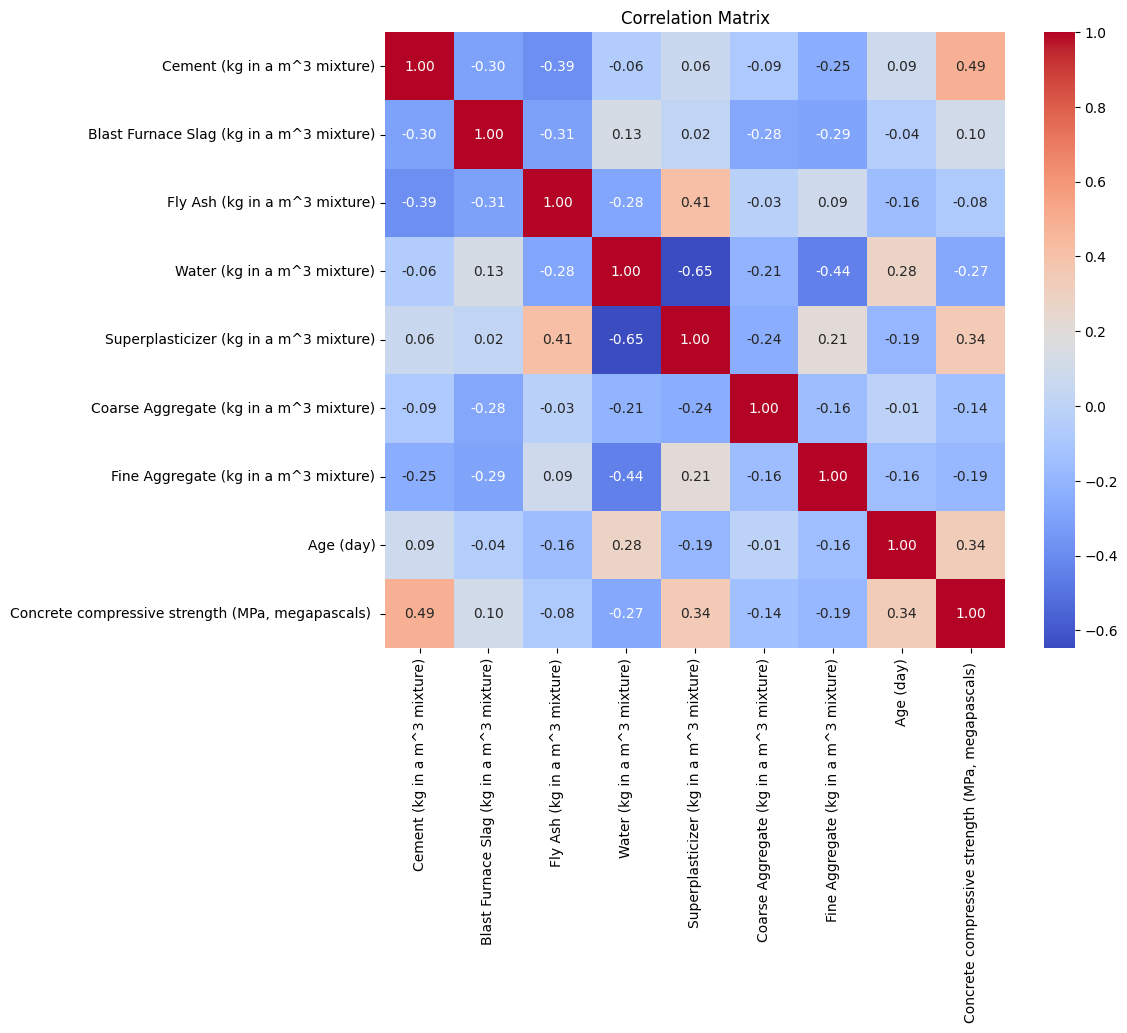

In [8]:
# Correlation Analysis
plt.figure(figsize=(10,8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Matrix")
plt.show()

## Data Preparation

In [10]:
# Separate Features and Target
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

In [11]:
# Train-Test Split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [12]:
# Feature Scaling - Because variables are measured in different units: Cement (kg/m³), Water (kg/m³), Age (days)
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Establish Mean-Prediction Baseline

In [14]:
# Calculate Mean Strength
mean_strength = y_train.mean()

print("Mean Strength =", mean_strength)

Mean Strength = 35.06680914403518


In [15]:
# Generate Baseline Predictions
import numpy as np

baseline_predictions = np.repeat(
    mean_strength,
    len(y_test)
)

### Evaluate Baseline

In [16]:
# Mean Absolute Error (MAE)
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

print("Baseline MAE:", mae)

Baseline MAE: 13.972284080563588


In [17]:
# Root Mean Squared Error (RMSE)
from sklearn.metrics import mean_squared_error
import numpy as np

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        baseline_predictions
    )
)

print("Baseline RMSE:", rmse)

Baseline RMSE: 17.29652082338367


In [18]:
# R² Score
from sklearn.metrics import r2_score

r2 = r2_score(
    y_test,
    baseline_predictions
)

print("Baseline R²:", r2)

Baseline R²: -0.0028206305715621216


## 2. Comparison of Linear and Non-Linear Modeling Approaches

In [19]:
# Linear Model: Multiple Linear Regression
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train_scaled, y_train)

lr_pred = lr.predict(X_test_scaled)

In [20]:
# Non-Linear Model: Random Forest Regressor
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

In [21]:
# Performance Evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

def evaluate(y_true, y_pred):

    mae = mean_absolute_error(y_true, y_pred)

    rmse = mean_squared_error(
        y_true,
        y_pred,
        squared=False
    )

    r2 = r2_score(y_true, y_pred)

    return mae, rmse, r2

In [25]:
# Evaluate both Models
# Use the training target mean as the baseline prediction
mean_pred = np.full(len(y_test), np.mean(y_train))

predictions = {
    "Mean Baseline": mean_pred,
    "Linear Regression": lr_pred,
    "Random Forest": rf_pred,
}

results = []
for model, pred in predictions.items():
    mae, rmse, r2 = evaluate(y_test, pred)
    results.append({
        "Model": model,
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2,
    })

results = pd.DataFrame(results)
display(results)

,Model,MAE,RMSE,R²
0,Mean Baseline,13.972284,17.296521,-0.002821
1,Linear Regression,8.896028,11.192200,0.580109
2,Random Forest,3.469942,5.119026,0.912162


### Residual Analysis

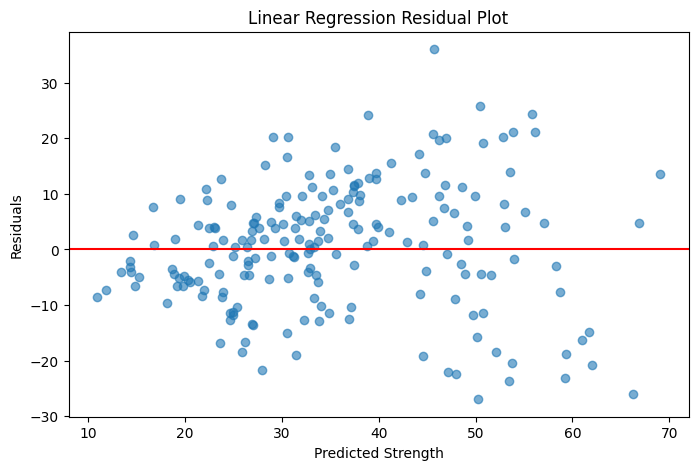

In [ ]:
# Residual = Actual - Predicted
# Residual Plot for Linear Regression
import matplotlib.pyplot as plt

lr_residuals = y_test - lr_pred

plt.figure(figsize=(8,5))

plt.scatter(
    lr_pred,
    lr_residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    color='red'
)

plt.xlabel("Predicted Strength")
plt.ylabel("Residuals")
plt.title("Linear Regression Residual Plot")
plt.show()

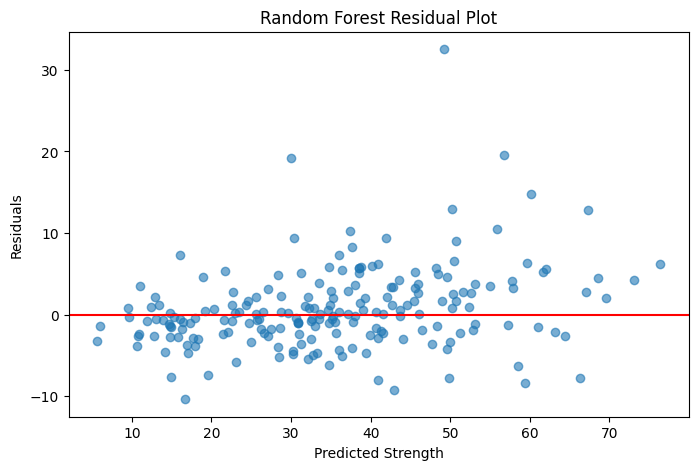

In [27]:
# Residual Plot for Random Forest
rf_residuals = y_test - rf_pred

plt.figure(figsize=(8,5))

plt.scatter(
    rf_pred,
    rf_residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    color='red'
)

plt.xlabel("Predicted Strength")
plt.ylabel("Residuals")
plt.title("Random Forest Residual Plot")
plt.show()

### Identifying Weak Prediction Regions

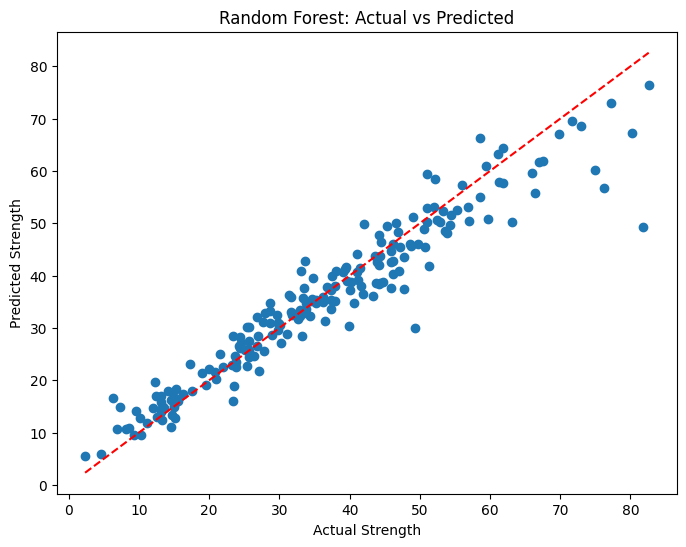

In [28]:
# Create an Actual vs Predicted plot
plt.figure(figsize=(8,6))

plt.scatter(y_test, rf_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Strength")
plt.ylabel("Predicted Strength")
plt.title("Random Forest: Actual vs Predicted")
plt.show()